# DFST Softmax Annealing and FST Extraction

Load a trained DFST_Softmax checkpoint, continue training with a fixed learning rate and exponentially increasing regularization, inspect the effective probability matrices, and extract a discrete FST. Hopcroft minimization produces the controller used for the transition table and exact PTO checks.

Run the notebook in the DEL environment. Source checkpoints remain unchanged; all new artifacts go to `OUTPUT_DIR`. For trajectory-based extraction from ordinary DFST controllers, use [Metric FST extraction](metric_FST_extraction.ipynb).

The default view displays the selected case in `analyses/`. To analyse another checkpoint, set `RECOMPUTE = True` and edit `CHECKPOINT_PATH` in Section 1. New outputs go to `analysis_outputs/`; published artifacts remain fixed.

In [1]:
from pathlib import Path
from copy import deepcopy
from datetime import datetime, timezone
import os
import yaml
import sys
import json
import math
import random
import hashlib

ROOT = Path(os.environ["DEL_REPO_ROOT"]) if os.environ.get("DEL_REPO_ROOT") else next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/differentiable_exact_learning").is_dir())
sys.path.insert(0, str(ROOT / "src"))

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, SVG
from differentiable_exact_learning.training import load_run
from differentiable_exact_learning.checkpoint import (
    atomic_save,
    atomic_json,
    capture_rng,
    restore_rng,
)
from differentiable_exact_learning.data import BatchSampler, build_static_dataset
from differentiable_exact_learning.objectives import action_loss, action_counts
from differentiable_exact_learning.analysis.extraction import (
    Transducer,
    extract_argmax,
    hopcroft_minimize,
    with_halt_state,
    number_states,
    verify_quotient,
    export_machine,
    compare_exact_ptos,
)
from differentiable_exact_learning.analysis.plot_style import (apply_paper_style, HEAT_CMAP, COLORS, heatmap_ticks, style_axes, paper_curve)

apply_paper_style()
from differentiable_exact_learning.analysis.release import analysis_cases, show_analysis_case

from differentiable_exact_learning.analysis.case_artifacts import (
    prepare_case, save_case_config, save_machine, select_case,
)
from differentiable_exact_learning.analysis.public_metadata import public_metadata


## 1. Choose and Load a Checkpoint

1. Set `RECOMPUTE = True` in the settings cell below.
2. Choose `CASE_INDEX` for the initial annealing recipe: 0 for `add2`, 1 for `mult2`, or 2 for `universal`.
3. Replace the `CHECKPOINT_PATH` assignment with your checkpoint file. For example, use `CHECKPOINT_PATH = ROOT / "runs/DFST_Softmax/mult2/hidden_64_data_100/final_model_checkpoint.pt"`. The default expression selects the published case's source checkpoint.
4. Review the annealing settings, `N_INPUTS`, `INPUT_LENGTH`, `DEVICE` and `OUTPUT_DIR` in the same cell. Run the imports, settings and checkpoint-loading cells in order.

**Accepted checkpoints.** Supply a complete DEL checkpoint for `DFST_Softmax`: released weights, a training snapshot, or an annealing snapshot. To select an intermediate training step, use the snapshot file directly, for example `CHECKPOINT_PATH = Path("/absolute/path/to/checkpoints/step_0000100000.pt")`. An annealed controller can use `ROOT / "analyses/annealing/DFST_Softmax/mult2/hidden_64_data_100/checkpoints/annealed_model_checkpoint.pt"`. Paths relative to `ROOT` and absolute paths both work. A bare model `state_dict` lacks the configuration and sampler state required by this procedure.

The checkpoint supplies the saved step, architecture, expert, training data settings, batch size, loss, optimizer type, weight decay, gradient clipping, curriculum and random-generator state. No separate step setting needs adjustment. `CASE_INDEX` supplies only the initial notebook settings and default path; changing `CHECKPOINT_PATH` loads the new checkpoint's own model and data configuration.

**Execution.** The loading cell prints the checkpoint path and saved step without updating weights. Stop after that cell to inspect the source. Continue through Sections 2 through 6 to anneal, extract the FST, render the plots and tables, and check exact PTO agreement on sampled inputs. Annealing starts with fresh optimizer moments and counts annealing updates from zero, including when the source already contains annealed weights. The finite check concerns the extracted FST; ULG/RLG evaluation of the neural checkpoint uses a separate workflow.

`LOG_EVERY` controls probability snapshots; step 0 and the final step are always saved. The final annealed checkpoint includes model, optimizer and random-generator state. `SAVE_INTERMEDIATES = True` also saves a full checkpoint at every snapshot step. `N_INPUTS` and `INPUT_LENGTH` control the final PTO check. All new files go to a fresh `OUTPUT_DIR`; an existing directory raises an error. Relative checkpoint and output paths resolve from the repository root. `DEL_ANALYSIS_DIR`, when set, supplies the default output path.

With `RECOMPUTE = False`, the notebook displays only the selected case and ignores the custom checkpoint. After changing checkpoints, restart the kernel and run the cells again in order to refresh every dependent result.
`SAVE_INTERMEDIATES = False` saves the compact case layout. Set `True` to also
retain debugging artifacts under `intermediates/`. This switch controls file
storage without changing the computation, final controller or measurements.
With `RECOMPUTE = False`, `CASE_INDEX` selects one published case; the notebook
reads saved artifacts without extraction or annealing.


Displaying published results. To analyse a checkpoint, set RECOMPUTE = True and edit CHECKPOINT_PATH above.


### Binary addition: annealing

Source run: `runs/DFST_Softmax/add2/hidden_22_data_75`

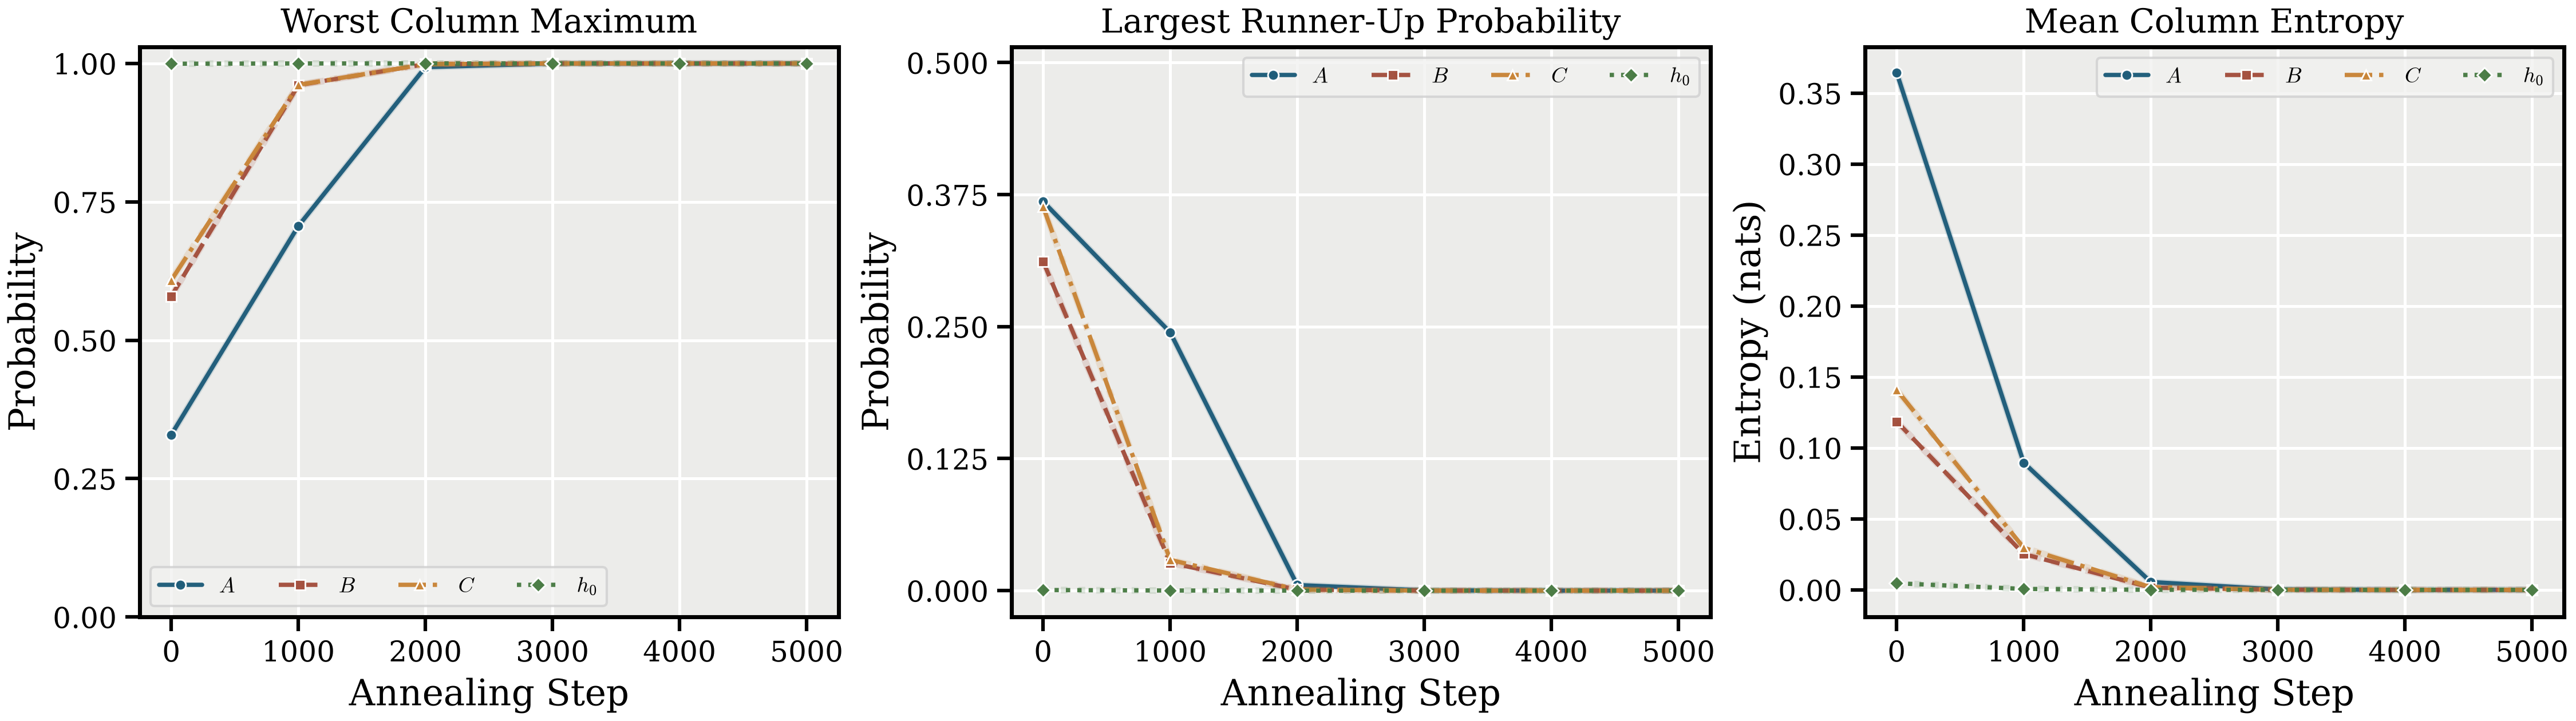

states                                                                17
defined_transitions                                                   68
proof_scope            Pairs of nonempty binary operands of arbitrary...
Name: Selected controller, dtype: object

,state,read,write,move,next_state
0,0,λ,λ,L,13
1,0,+,+,L,7
2,0,0,0,R,0
3,0,1,1,R,0
4,1,λ,1,D,5
...,...,...,...,...,...
63,15,1,1,R,4
64,16,λ,λ,S,16
65,16,+,+,S,16
66,16,0,0,S,16


all_exact        True
exact_matches     100
failures            0
input_length      100
inputs            100
Name: Saved PTO comparison, dtype: object

controller                       add2_annealing_20261102T145507Z
source_hashes_match                                         True
csv_matches_json                                            True
expert_equals_add_grid_2                                    True
protocol_phases                                               27
reachable_phase_state_pairs                                   30
checked_protocol_edges                                        52
covered_nonhalt_table_entries                                 37
Name: Saved verification report, dtype: object

[Case notes](../analyses/annealing/DFST_Softmax/add2/hidden_22_data_75/README.md) · [Machine](../analyses/annealing/DFST_Softmax/add2/hidden_22_data_75/machines/extracted.json) · [Transition table](../analyses/annealing/DFST_Softmax/add2/hidden_22_data_75/machines/extracted.pdf) · [Proof](../analyses/annealing/DFST_Softmax/add2/hidden_22_data_75/proof/equivalence_proof.pdf) · [Checker](../analyses/annealing/DFST_Softmax/add2/hidden_22_data_75/proof/verify_equivalence.py)

In [2]:
# Set True to use CHECKPOINT_PATH and run the annealing workflow.
RECOMPUTE = False
SAVE_INTERMEDIATES = False

# Published recipe: 0 = add2, 1 = mult2, 2 = universal.
CASE_INDEX = 0
CASES = analysis_cases(ROOT, "annealing")
case = select_case(CASES, CASE_INDEX)
CASE_CONFIG = yaml.safe_load((ROOT / case["path"] / "config.yaml").read_text())

# Replace this expression with your checkpoint file, for example:
# CHECKPOINT_PATH = Path("/absolute/path/to/checkpoints/step_0000100000.pt")
CHECKPOINT_PATH = ROOT / CASE_CONFIG["source_run"] / "final_model_checkpoint.pt"

# These values come from the selected recipe; edit them for a new experiment.
LAMBDA_START = CASE_CONFIG["lambda_start"]
LAMBDA_END = CASE_CONFIG["lambda_end"]
LEARNING_RATE = CASE_CONFIG["learning_rate"]
ANNEAL_STEPS = CASE_CONFIG["steps"]
LOG_EVERY = CASE_CONFIG["log_every"]

# Exact PTO comparison of the extracted FST.
N_INPUTS = 100
INPUT_LENGTH = 100

OUTPUT_DIR = Path(os.environ.get("DEL_ANALYSIS_DIR", ROOT / "analysis_outputs" / f"annealing_{datetime.now(timezone.utc):%Y%m%dT%H%M%S%fZ}"))
# Use a CUDA-compatible DEL environment, or choose "cpu" explicitly.
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

if not RECOMPUTE:
    print("Displaying published results. To analyse a checkpoint, set RECOMPUTE = True and edit CHECKPOINT_PATH above.")
    show_analysis_case(ROOT, case)


In [ ]:
if RECOMPUTE:
    source = Path(CHECKPOINT_PATH).expanduser()
    if not source.is_absolute():
        source = ROOT / source
    source = source.resolve()
    if not source.is_file():
        raise FileNotFoundError(f"Set CHECKPOINT_PATH to an existing checkpoint file: {source}")
    model, expert, config, saved = load_run(source, device=DEVICE)
    if config["model"]["name"] != "DFST_Softmax":
        raise TypeError("This notebook requires a DFST_Softmax checkpoint")
    OUTPUT_DIR = Path(OUTPUT_DIR).expanduser()
    if not OUTPUT_DIR.is_absolute():
        OUTPUT_DIR = ROOT / OUTPUT_DIR
    OUTPUT_DIR = OUTPUT_DIR.resolve()
    print(f"Loaded {source}")
    print(f"New analysis outputs: {OUTPUT_DIR}")
    display(
        pd.Series(
            {
                "checkpoint_step": saved["step"],
                "model": config["model"]["name"],
                "batch_size": config["training"]["batch_size"],
                "loss": config["training"]["loss"],
                "optimizer": config["training"]["optimizer"],
                "data_source": config["data"]["source"],
                "training_length": saved["curriculum_length"],
            },
            name="Checkpoint settings",
        )
    )

## 2. Continue Training with Lambda Annealing

For update $u=1,\ldots,T$, use a constant learning rate and
$$\lambda_u=\lambda_{\mathrm{start}}\left(\frac{\lambda_{\mathrm{end}}}{\lambda_{\mathrm{start}}}\right)^{(u-1)/(T-1)}.$$
Both endpoints must exceed zero and $T\ge2$. The objective uses $L_{\mathrm{PTO}}+\lambda_uR$, where
$$R=\sum_{M\in\{A,B,C\}}\operatorname{mean}_{x,q}\left[1-\sum_iM[x,i,q]^2\right]+1-\sum_i h_0[i]^2.$$

The penalty acts on the effective matrices, including learned token embeddings, and reaches zero at one-hot columns. The source loss, masking, data sampler and clipping are retained. Any curriculum starts at the saved length and retains the original settings and cadence.

Each snapshot saves effective probabilities. The final checkpoint saves model weights and optimizer/RNG state; `SAVE_INTERMEDIATES = True` also retains intermediate checkpoints. The notebook controls the lambda schedule; the stock constant-lambda trainer does not resume this schedule automatically.


In [ ]:
def geometric_value(update, steps, start, final):
    if isinstance(steps, bool) or not isinstance(steps, int) or steps < 2:
        raise ValueError("steps must be an integer >= 2")
    if not all(math.isfinite(v) and v > 0 for v in (start, final)):
        raise ValueError("Exponential endpoints must be finite and strictly positive")
    if not 1 <= update <= steps:
        raise ValueError("update must be in 1..steps")
    if update == 1:
        return float(start)
    if update == steps:
        return float(final)
    r = (update - 1) / (steps - 1)
    return math.exp((1 - r) * math.log(start) + r * math.log(final))


def peaking_penalty(model):
    A, B, C, h0 = model.effective_tensors()
    return sum((1 - p.square().sum(-2)).mean() for p in (A, B, C)) + 1 - h0.square().sum()


@torch.no_grad()
def probability_snapshot(model):
    tensors = {
        k: p.detach().cpu().clone()
        for k, p in zip(("A", "B", "C", "h0"), model.effective_tensors())
    }
    for name, p in tensors.items():
        sums = p.sum(-1 if name == "h0" else -2)
        if (
            not torch.isfinite(p).all()
            or p.min() < -1e-6
            or not torch.allclose(sums, torch.ones_like(sums), atol=1e-5)
        ):
            raise ValueError(f"{name} is not a finite probability tensor")
    return tensors


def sharpness_rows(tensors, step):
    rows = []
    for name, p in tensors.items():
        p = p[:, None] if name == "h0" else p
        maximum = p.max(-2).values
        second = (
            p.topk(2, dim=-2).values[..., 1, :] if p.shape[-2] > 1 else torch.zeros_like(maximum)
        )
        rows.append(
            dict(
                step=step,
                tensor="h_0" if name == "h0" else name,
                columns=maximum.numel(),
                worst_max=float(maximum.min()),
                worst_second=float(second.max()),
                mean_entropy=float(
                    -(p * p.clamp_min(torch.finfo(p.dtype).tiny).log()).sum(-2).mean()
                ),
            )
        )
    return rows

In [ ]:
def run_annealing(model, expert, config, saved, source, output_dir):
    geometric_value(1, ANNEAL_STEPS, LAMBDA_START, LAMBDA_END)
    if LAMBDA_END < LAMBDA_START:
        raise ValueError("LAMBDA_END must be at least LAMBDA_START")
    if not math.isfinite(LEARNING_RATE) or LEARNING_RATE <= 0:
        raise ValueError("LEARNING_RATE must be finite and positive")
    if isinstance(LOG_EVERY, bool) or not isinstance(LOG_EVERY, int) or LOG_EVERY < 1:
        raise ValueError("LOG_EVERY must be a positive integer")
    output_dir = Path(output_dir).expanduser().resolve()
    probability_snapshot(model)
    prepare_case(output_dir, SAVE_INTERMEDIATES)

    data, training = deepcopy(config["data"]), deepcopy(config["training"])
    traces = (
        build_static_dataset(data, cache_dir=ROOT / ".cache/annealing_data")
        if data["source"] == "static"
        else None
    )
    sampler = random.Random()
    restore_rng(saved["rng"], sampler)
    batches = BatchSampler(expert, sampler, training["batch_size"], traces=traces)
    optimizer_class = {"adam": torch.optim.Adam, "adamw": torch.optim.AdamW}[training["optimizer"]]
    optimizer = optimizer_class(
        model.parameters(), lr=LEARNING_RATE, weight_decay=training["weight_decay"]
    )
    device = next(model.parameters()).device
    length = saved["curriculum_length"]
    curriculum = training["arithmetic_curriculum"]
    aggregate = dict(loss=0.0, correct=0, tokens=0, updates=0)
    spec = dict(
        source=str(source),
        source_sha256=hashlib.sha256(source.read_bytes()).hexdigest(),
        source_step=saved["step"],
        steps=ANNEAL_STEPS,
        lambda_start=LAMBDA_START,
        lambda_end=LAMBDA_END,
        learning_rate=LEARNING_RATE,
        log_every=LOG_EVERY,
        device=str(device),
        source_config=config,
        torch_version=str(torch.__version__),
        penalty="effective_column_gini_plus_h0",
        optimizer="fresh_" + training["optimizer"],
        rng="restored from source checkpoint",
    )
    save_case_config(output_dir, spec)
    history, diagnostics, paths = [], [], {}
    print(
        f"Loaded {source}\nBatch size: {training['batch_size']} | loss: {training['loss']} | "
        f"data: {data['source']} | optimizer: {training['optimizer']} | length: {length}"
    )

    def snapshot(step, coefficient):
        model.eval()
        tensors = probability_snapshot(model)
        diagnostics.extend(sharpness_rows(tensors, step))
        checkpoint_config = deepcopy(config)
        checkpoint_config["model"]["reg_lambda"] = coefficient
        checkpoint_config["training"].update(
            steps=ANNEAL_STEPS,
            lr=LEARNING_RATE,
            final_lr=LEARNING_RATE,
            warmup_steps=0,
            checkpoint_every=LOG_EVERY,
        )
        checkpoint_config["run"].update(
            name=output_dir.name, device=str(device), output_dir=str(output_dir.parent)
        )
        checkpoint_config["run"]["wandb"]["enabled"] = False
        checkpoint_config["evaluation"].update(every=0, final=False)
        state = dict(
            format_version=1,
            config=checkpoint_config,
            expert_digest=saved["expert_digest"],
            step=step,
            model=model.state_dict(),
            optimizer=optimizer.state_dict(),
            rng=capture_rng(sampler),
            curriculum_length=length,
            aggregate=aggregate.copy(),
            initialization=dict(checkpoint=str(source), source_step=saved["step"]),
            annealing=spec,
        )
        if SAVE_INTERMEDIATES:
            atomic_save(public_metadata(state), output_dir / "intermediates/checkpoints" / f"step_{step:010d}.pt")
        if step == ANNEAL_STEPS:
            atomic_save(public_metadata(state), output_dir / "checkpoints/annealed_model_checkpoint.pt")
        path = output_dir / "data/probabilities" / f"step_{step:010d}.pt"
        atomic_save(tensors, path)
        paths[step] = path
        pd.DataFrame(diagnostics).to_csv(output_dir / "data/sharpness.csv", index=False)
        print(f"Saved iteration {step}: lambda={coefficient:.3g}", flush=True)
        model.train()

    snapshot(0, float(config["model"]["reg_lambda"]))
    for update in range(1, ANNEAL_STEPS + 1):
        coefficient = geometric_value(update, ANNEAL_STEPS, LAMBDA_START, LAMBDA_END)
        model.reg_lambda = coefficient
        batch = batches.sample(length).to(device)
        optimizer.zero_grad(set_to_none=True)
        symbol, motion, _ = model(batch.inputs, mask=batch.mask)
        supervised = action_loss(
            symbol,
            motion,
            batch.symbols,
            batch.motions,
            batch.mask,
            inputs=batch.inputs,
            inverse_freq_alpha=training["inverse_freq_alpha"],
            loss=training["loss"],
            output_kind=model.output_kind,
        )
        penalty = peaking_penalty(model)
        objective = supervised + coefficient * penalty
        if not torch.isfinite(objective):
            raise FloatingPointError(f"Nonfinite loss at update {update}")
        objective.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(), training["grad_clip"], error_if_nonfinite=True
        )
        optimizer.step()
        if not all(torch.isfinite(p).all() for p in model.parameters()):
            raise FloatingPointError(f"Nonfinite parameters at update {update}")
        correct, tokens, _ = action_counts(
            symbol.detach(), motion.detach(), batch.symbols, batch.motions, batch.mask
        )
        row = dict(
            step=update,
            reg_lambda=coefficient,
            lr=LEARNING_RATE,
            supervised_loss=float(supervised.detach()),
            peaking=float(penalty.detach()),
            weighted_penalty=float((coefficient * penalty).detach()),
            objective=float(objective.detach()),
            train_action_accuracy=correct / tokens,
            grad_norm=float(grad_norm),
            curriculum_length=length,
        )
        history.append(row)
        with (output_dir / "data/training.jsonl").open("a") as stream:
            stream.write(json.dumps(row, allow_nan=False) + "\n")
        aggregate["loss"] += row["supervised_loss"]
        aggregate["correct"] += correct
        aggregate["tokens"] += tokens
        aggregate["updates"] += 1
        # Retain the source curriculum's settings and update cadence.
        if update % training["log_every"] == 0:
            if (
                curriculum["enabled"]
                and aggregate["correct"] / aggregate["tokens"] >= curriculum["accuracy_threshold"]
            ):
                length = min(length + 1, data["max_length"])
            aggregate = dict(loss=0.0, correct=0, tokens=0, updates=0)
        if update % LOG_EVERY == 0 or update == ANNEAL_STEPS:
            print(
                f"update={update}/{ANNEAL_STEPS} lambda={coefficient:.3g} "
                f"PTO={row['supervised_loss']:.6g} R={row['peaking']:.6g} "
                f"training accuracy={row['train_action_accuracy']:.2%}",
                flush=True,
            )
            snapshot(update, coefficient)
    return dict(
        model=model,
        expert=expert,
        config=config,
        paths=paths,
        history=pd.DataFrame(history),
        sharpness=pd.DataFrame(diagnostics),
        output_dir=output_dir,
    )


In [ ]:
if RECOMPUTE:
    result = run_annealing(model, expert, config, saved, source, OUTPUT_DIR)
    print("Saved snapshots:", list(result["paths"]))

## 3. Inspect the Probability Columns

The snapshots show A/B/C for every input symbol and the initial distribution h₀. Columns represent current states; rows represent successor states, written symbols or motions. The paper's terracotta palette uses a fixed **linear [0,1] probability scale**, with at most five ticks per axis and identical state ordering across snapshots.

The table contains six fields:

| Field | Meaning |
| --- | --- |
| `step` | Completed annealing updates; 0 denotes the source checkpoint. |
| `tensor` | A, B, C, or h₀. |
| `columns` | Number of probability columns, counting all input symbols; h₀ counts as one. |
| `worst_max` | Smallest column maximum. Approaches 1 as every column concentrates on one entry. |
| `worst_second` | Largest second-highest probability across columns. Approaches 0 as competing entries disappear. |
| `mean_entropy` | Mean column entropy, using natural logarithms (nats). Approaches 0 for one-hot columns. |

The two worst cases can occur in different columns. The three plots track these quantities for A, B, C and h₀; entropy ranges differ with the number of rows in each tensor.

### Browse Probability Snapshots

The viewer loads only the selected case. **Annealing Step** selects a saved
probability snapshot; **Read Symbol** selects the corresponding matrices.
The lower strip displays the initial-state distribution. Sliders use the
saved tensors without interpolation or retraining. The shared palette and
fixed probability scale support comparisons across steps.

With `RECOMPUTE = True`, the viewer reads the completed annealing output.
Install `pip install -e '.[analysis]'` and use a widget-enabled notebook editor.


In [3]:
from io import BytesIO
from functools import lru_cache

from differentiable_exact_learning.data import create_expert


def make_annealing_viewer(directory, title):
    """Browse saved probability tensors without rerunning annealing."""
    import ipywidgets as widgets

    directory = Path(directory)
    recipe = yaml.safe_load((directory / "config.yaml").read_text())
    source_config = (yaml.safe_load((ROOT / recipe["source_run"] / "config.yaml").read_text())
                     if "source_run" in recipe else recipe["source_config"])
    viewer_expert = create_expert(source_config["data"])
    snapshots = {
        int(path.stem.removeprefix("step_")): torch.load(
            path, map_location="cpu", weights_only=True
        )
        for path in sorted((directory / "data/probabilities").glob("step_*.pt"))
    }
    if not snapshots or min(snapshots) != 0 or max(snapshots) != recipe["steps"]:
        raise ValueError(f"Expected probability snapshots at step 0 and the configured final step: {directory}")

    step_slider = widgets.SelectionSlider(
        options=[(f"{step:,}", step) for step in snapshots], value=0,
        description="Annealing Step", continuous_update=False,
        style={"description_width": "initial"}, layout=widgets.Layout(width="620px"),
    )
    token_selector = widgets.Dropdown(
        options=[(viewer_expert.vocab_rev[x] or "λ", x)
                 for x in range(viewer_expert.input_size)],
        description="Read Symbol", style={"description_width": "initial"},
        layout=widgets.Layout(width="220px"),
    )
    picture = widgets.Image(format="png", layout=widgets.Layout(width="100%"))

    @lru_cache(maxsize=64)
    def render(step, token):
        tensors = snapshots[step]
        fig = plt.figure(figsize=(13, 5.8), constrained_layout=True)
        grid = fig.add_gridspec(2, 3, height_ratios=[4, 0.65])
        axes = [fig.add_subplot(grid[0, index]) for index in range(3)]
        for ax, name in zip(axes, ("A", "B", "C")):
            probability = tensors[name][token]
            image = ax.imshow(probability.numpy(), vmin=0, vmax=1,
                              aspect="auto", interpolation="nearest", cmap=HEAT_CMAP)
            labels = (list(range(probability.shape[0])) if name == "A" else
                      [(viewer_expert.vocab_rev if name == "B" else
                        viewer_expert.motion_vocab_rev)[i] or "λ"
                       for i in range(probability.shape[0])])
            heatmap_ticks(ax, probability.shape, ylabels=labels)
            ax.set(xlabel="Current State", title=f"${name}[x]$",
                   ylabel={"A": "Next State", "B": "Written Symbol", "C": "Motion"}[name])
        initial = fig.add_subplot(grid[1, :])
        probability = tensors["h0"].reshape(1, -1)
        initial.imshow(probability.numpy(), vmin=0, vmax=1, aspect="auto",
                       interpolation="nearest", cmap=HEAT_CMAP)
        heatmap_ticks(initial, probability.shape, ylabels=["$h_0$"])
        initial.set_xlabel("Initial State Coordinate")
        colorbar = fig.colorbar(image, ax=[*axes, initial], ticks=np.linspace(0, 1, 5),
                               label="Probability", shrink=0.9, pad=0.02)
        colorbar.ax.minorticks_off()
        token_name = viewer_expert.vocab_rev[token] or "λ"
        fig.suptitle(f"{title} · Annealing Step {step:,} · Read Symbol {token_name}", fontsize=14)
        buffer = BytesIO()
        try:
            fig.savefig(buffer, format="png", dpi=110)
            return buffer.getvalue()
        finally:
            plt.close(fig)

    def update(_=None):
        picture.value = render(step_slider.value, token_selector.value)

    step_slider.observe(update, names="value")
    token_selector.observe(update, names="value")
    update()
    controls = widgets.HBox([step_slider, token_selector], layout=widgets.Layout(flex_flow="row wrap"))
    return widgets.VBox([controls, picture], layout=widgets.Layout(width="100%", max_width="1300px"))


### Selected Agent


In [4]:
viewer_directory = OUTPUT_DIR if RECOMPUTE else ROOT / case["path"]
display(make_annealing_viewer(viewer_directory, case["title"]))


In [ ]:
if RECOMPUTE and SAVE_INTERMEDIATES:
    def plot_snapshot(tensors, expert, step, coefficient, directory):
        for x in range(expert.input_size):
            fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), constrained_layout=True)
            for ax, name in zip(axes, ("A", "B", "C")):
                p = tensors[name][x]
                image = ax.imshow(
                    p.numpy(), vmin=0, vmax=1, aspect="auto", interpolation="nearest", cmap=HEAT_CMAP
                )
                labels = (
                    list(range(p.shape[0]))
                    if name == "A"
                    else [
                        (expert.vocab_rev if name == "B" else expert.motion_vocab_rev)[i] or "λ"
                        for i in range(p.shape[0])
                    ]
                )
                heatmap_ticks(ax, p.shape, ylabels=labels)
                ax.set(
                    xlabel="Current State",
                    title=f"${name}$",
                    ylabel={"A": "Next State", "B": "Written Symbol", "C": "Motion"}[name],
                )
            colorbar = fig.colorbar(
                image,
                ax=axes.tolist(),
                label="Probability",
                ticks=np.linspace(0, 1, 5),
                shrink=0.86,
                pad=0.02,
            )
            colorbar.ax.minorticks_off()
            colorbar.outline.set_linewidth(1.7)
            token = expert.vocab_rev[x] or "λ"
            fig.suptitle(
                f"Probability Matrices at Step {step:,} (Input {token}, λ = {coefficient:.3g})",
                fontsize=14,
            )
            stem = directory / f"matrices_{step:010d}_token_{x}"
            for extension in ("png", "pdf"):
                fig.savefig(stem.with_suffix(f".{extension}"), dpi=300)
            display(Image(filename=str(stem.with_suffix(".png"))))
            plt.close(fig)
        fig, ax = plt.subplots(figsize=(10, 2.2), constrained_layout=True)
        image = ax.imshow(
            tensors["h0"][None, :],
            vmin=0,
            vmax=1,
            aspect="auto",
            interpolation="nearest",
            cmap=HEAT_CMAP,
        )
        heatmap_ticks(ax, (1, tensors["h0"].numel()), ylabels=["$h_0$"])
        ax.set(xlabel="Initial State Coordinate", title=f"Initial-State Probabilities at Step {step:,}")
        colorbar = fig.colorbar(image, ax=ax, ticks=np.linspace(0, 1, 5), label="Probability", pad=0.02)
        colorbar.ax.minorticks_off()
        colorbar.outline.set_linewidth(1.7)
        for extension in ("png", "pdf"):
            fig.savefig(directory / f"h0_{step:010d}.{extension}", dpi=300)
        display(Image(filename=str(directory / f"h0_{step:010d}.png")))
        plt.close(fig)


    (result["output_dir"] / "intermediates/probability_figures").mkdir(parents=True, exist_ok=True)
    for step in result["paths"]:
        tensors = torch.load(
            result["output_dir"] / "data/probabilities" / f"step_{step:010d}.pt", weights_only=True
        )
        coefficient = (
            config["model"]["reg_lambda"]
            if step == 0
            else geometric_value(step, ANNEAL_STEPS, LAMBDA_START, LAMBDA_END)
        )
        plot_snapshot(tensors, expert, step, coefficient, result["output_dir"] / "intermediates/probability_figures")
    display(result["sharpness"])


In [ ]:
if RECOMPUTE:
    sharpness = result["sharpness"]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
    metrics = (
        ("worst_max", "Worst Column Maximum", "Probability"),
        ("worst_second", "Largest Runner-Up Probability", "Probability"),
        ("mean_entropy", "Mean Column Entropy", "Entropy (nats)"),
    )
    for ax, (metric, title, ylabel) in zip(axes, metrics):
        for index, (name, label, marker, line) in enumerate(
            (
                ("A", "$A$", "o", "-"),
                ("B", "$B$", "s", "--"),
                ("C", "$C$", "^", "-."),
                ("h_0", "$h_0$", "D", ":"),
            )
        ):
            frame = sharpness[sharpness.tensor == name].sort_values("step")
            paper_curve(
                ax,
                frame.step,
                frame[metric],
                color=COLORS[index],
                label=label,
                marker=marker,
                linestyle=line,
            )
        ax.set(xlabel="Annealing Step", ylabel=ylabel, title=title)
        ax.set_ylim(bottom=0)
        if metric == "worst_max":
            ax.set(ylim=(0, 1.03), yticks=np.linspace(0, 1, 5))
        elif metric == "worst_second":
            ax.set(ylim=(-0.025, 0.515), yticks=np.linspace(0, 0.5, 5))
        else:
            # Leave space below zero so near-zero entropy remains visible.
            upper = ax.get_ylim()[1]
            ax.set_ylim(bottom=-0.05 * upper)
            ax.set_yticks([tick for tick in ax.get_yticks() if 0 <= tick <= upper])
        style_axes(ax)
        ax.legend(ncol=4, loc="best")
    for extension in ("png", "pdf"):
        fig.savefig(result["output_dir"] / "figures" / f"sharpness_evolution.{extension}", dpi=300)
    display(Image(filename=str(result["output_dir"] / "figures/sharpness_evolution.png")))
    plt.close(fig)


## 4. Extract and Minimize the FST

For input x and current state q, take column argmax in A/B/C and start at `argmax(h0)`. B/C read the pre-transition state, matching the model. Keep all reachable states and minimize the complete Mealy transducer with Hopcroft partition refinement.

The quotient check verifies every transition, output and state mapping. Minimization preserves the extracted FST exactly; the quotient check does not establish equivalence with the continuous DFST_Softmax.

Redirect every `S` transition to a dedicated final state, preserving the written symbol. The final state has a `HALT, x → HALT | x | S` self-loop for every read symbol. These loops specify behavior after stopping; the loops do not add observed evidence. All other unknown transitions remain unknown. Apply Hopcroft minimization to this normalized controller, then number the states with the halt state last. If no reachable stopping edge exists, retain an unreachable halt row explicitly. PTOs through the first `S` remain unchanged; equivalence for arbitrary continuations after `S` is not asserted.


In [ ]:
if RECOMPUTE:
    extracted = extract_argmax(result["model"])
    extracted = with_halt_state(extracted, expert.motion_vocab["S"])
    machine, state_map = hopcroft_minimize(extracted)
    # Retain an explicit halt row even when no observed transition reaches it.
    if not machine.final_states:
        machine = with_halt_state(machine, expert.motion_vocab["S"])
    machine, numbering = number_states(machine)
    state_map = {q: numbering[reduced] for q, reduced in state_map.items()}
    assert verify_quotient(extracted, machine, state_map)
    if SAVE_INTERMEDIATES:
        export_machine(extracted, result["output_dir"] / "intermediates/argmax_fst")
    atomic_json({str(q): v for q, v in state_map.items()}, result["output_dir"] / "machines/state_map.json")
    print(
        f"Reachable states: {len(extracted.states)} → {len(machine.states)} after Hopcroft minimization"
    )


## 5. Display the Transition Table

Rows denote current states; columns denote read symbols. Each defined cell contains `next state | written symbol | motion`; `λ` denotes blank and `-` denotes an unobserved transition. Typewriter state numbers distinguish controller states from symbol digits. State numbering starts at 0, with explicit halt states placed last, and matches every machine and state-map export.

The parchment table uses a green initial row and a rose halt row. A controller without an explicit halt state has no halt row; the controller’s `S` actions terminate execution. PDF exports embed the fonts. Readable CSV files support inspection, and SVG panels render inline. Larger tables span several panels, each with a repeated header.

In [ ]:
if RECOMPUTE:
    table_paths = save_machine(machine, expert, result["output_dir"] / "machines", "extracted")
    for panel in table_paths["panels"]:
        display(SVG(data=panel))
    reference = Transducer(
        {
            (q, expert.vocab[x]): (target, expert.vocab[symbol], expert.motion_vocab[motion])
            for (q, x), (target, symbol, motion) in expert.transitions.items()
        },
        0,
        tuple(range(expert.input_size)),
        frozenset([expert.halt_state]),
    )
    reference, expert_numbering = number_states(reference)
    atomic_json(
        {str(q): reduced for q, reduced in expert_numbering.items()},
        result["output_dir"] / "machines/expert_state_map.json",
    )
    expert_table_paths = save_machine(reference, expert, result["output_dir"] / "machines", "expert")
    for panel in expert_table_paths["panels"]:
        display(SVG(data=panel))
    print("Transition tables:", table_paths["pdf"], expert_table_paths["pdf"])


## 6. Check Exact PTO Agreement

Set `N_INPUTS` and `INPUT_LENGTH` in Section 1 to choose the number of test inputs and the exact input length. For arithmetic, both operands have this length; for teleporting controllers, the setting specifies binary input length, with tasks from the checkpoint. Inputs are sampled with replacement using a copy of the saved sampler state.

The check streams expert PTOs and stops each comparison at the first differing action. Agreement on every write and move implies identical memory and subsequent reads, so a full match, including halt, establishes exact PTO agreement on that input. The check requires no separate rollout limit. Failures include the input and first mismatch; results are saved to `checks/pto_comparison.json`.

These finite checks support inspection and counterexample discovery. Agreement on the tested inputs does not prove agreement for all possible inputs.

In [ ]:
if RECOMPUTE:
    pto_rng = random.Random()
    pto_rng.setstate(saved["rng"]["sampler"])
    report = compare_exact_ptos(machine, expert, N_INPUTS, INPUT_LENGTH, pto_rng)
    atomic_json(report, result["output_dir"] / "checks/pto_comparison.json")
    status = "PASS" if report["all_exact"] else "FAIL"
    print(
        f"{status}: {report['exact_matches']}/{N_INPUTS} exact PTO matches; "
        f"{report['failures']} failures; input length {INPUT_LENGTH}."
    )
    failures = [row for row in report["results"] if not row["exact_match"]]
    if failures:
        display(pd.json_normalize(failures))
    print("Outputs:", result["output_dir"])


## Proof Scope

The published proofs concern the extracted discrete controllers on the valid inputs specified in each theorem. The finite checker verifies local obligations and supplementary executions. The accompanying mathematical argument establishes protocol coverage. Agreement on finitely many inputs does not establish the corresponding claim for the continuous neural controller.

## Output Files

`OUTPUT_DIR` uses the following layout:

| Path | Contents |
|---|---|
| `config.yaml` | Source checkpoint reference, checksum and method settings |
| `machines/extracted.{json,csv,pdf}` | Final extracted controller and readable transition maps |
| `machines/expert.{json,csv,pdf}` | Expert controller and readable transition maps |
| `machines/*state_map.json` | State mappings used by minimization and numbering |
| `figures/` | Main plots in PDF and PNG |
| `data/` | Plot measurements, sampled extraction inputs or annealing probability snapshots |
| `checks/` | Sampled PTO results, counterexamples and supporting checks |
| `checkpoints/annealed_model_checkpoint.pt` | Final annealed weights and continuation state, for annealing only |
| `intermediates/` | Debugging artifacts, written only with `SAVE_INTERMEDIATES = True` |

Published cases additionally contain `README.md` and an independent `proof/`
bundle. The notebooks do not construct equivalence proofs automatically.
Metric extraction retains every row of the stability measurements in either
storage mode. Annealing retains the probability snapshots needed by the viewer
in either mode. SVG panels render inline without permanent SVG or LaTeX exports.
